### Intro
The target audience includes public health policy officials and workplace health workers.

This presentation tries to argue that there is significant reason to research the potential negative effects of relationship separation on a person's health in the long-term. This is mainly done by comparing health attributes for both married and unmarried/divorced individuals. The hypothsis is that more research in this area may conclude that better health policies are needed to support such individuals.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

### Sources
- Survey data is from MIDUS 2 Project 1 Cross-Sectional Survey (ICPSR 04652, N=4,963).
- Biomarker data is from MIDUS 2 Project 4 Biomarker Study (ICPSR 29282, N=1,255).

### Cleaning
- Convert missing codes (7, 8, 9, -1) to NaN.
- Some participants are missing marital status.
- 'Poor' is at 5 while 'Excellent' is at 1 so graph may give wrong first impression.
- Grouped age as <55 and 55+ and also grouped education.
- Most people from the biomarker data are not present in the survey data.

In [2]:
raw_survey = pd.read_csv('04652-0001-Data.tsv', sep='\t')
raw_bio = pd.read_csv('29282-0001-Data.tsv', sep='\t')

cols = ['M2ID', 'B1PB19', 'B1PA1', 'B1PA15', 'B1PA2', 'B1PRSEX', 'B1PAGE_M2', 'B1PB1']
df_s = raw_survey[cols].copy()

# Rule 1: Replace missing codes
for col in ['B1PB19', 'B1PA1', 'B1PA15', 'B1PA2', 'B1PB1']:
    df_s[col] = df_s[col].replace([7, 8, 9, 97, 98, 99, -1], np.nan)

# Rule 2: Cohort Filtering (drops 6 missing marital cases)
df_clean = df_s.dropna(subset=['B1PB19']).copy()

# Rule 3: Scale Inversion & Mappings
marital_map = {1: 'Married', 2: 'Separated', 3: 'Divorced', 4: 'Widowed', 5: 'Never Married'}
df_clean['marital_status'] = df_clean['B1PB19'].map(marital_map)
df_clean['phys_health'] = 6 - df_clean['B1PA1']
df_clean['mental_health'] = 6 - df_clean['B1PA15']
df_clean['gender'] = df_clean['B1PRSEX'].map({1: 'Male', 2: 'Female'})
df_clean['chronic_count'] = df_clean['B1PA2']
df_clean['age'] = df_clean['B1PAGE_M2']
df_clean['education_code'] = df_clean['B1PB1']

# Rule 4: Feature Engineering
df_clean['age_group'] = np.where(df_clean['age'] < 55, 'Midlife (<55)', 'Older Adult (55+)')
df_clean['education_tier'] = pd.cut(df_clean['education_code'], bins=[0, 5, 8, 12], labels=['Low Education', 'Medium Education', 'High Education'])

# Rule 5: Biomarker Relational Merge
df_b = raw_bio[['M2ID', 'B4BFGN']].copy()
df_b['B4BFGN'] = df_b['B4BFGN'].replace([999998, 999999, -1], np.nan)
df_merged = pd.merge(df_clean, df_b, on='M2ID', how='inner')

print('Raw survey rows:', len(raw_survey))
print('Cleaned survey rows:', len(df_clean))
print('Merged biomarker rows:', len(df_merged))

Raw survey rows: 4963
Cleaned survey rows: 4957
Merged biomarker rows: 1052


C:\Users\Dvt-Est\AppData\Local\Temp\ipykernel_4324\3047612439.py:2: DtypeWarning: Columns (2506: B4AD414) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_bio = pd.read_csv('29282-0001-Data.tsv', sep='\t')


### Statistical interpretation of the data
Below we calculate group means, standard deviations, variances, independent two-sample $t$-tests, and Levene's test for variance equality.

In [3]:
# Physical Health Summary & t-test
phys_summary = df_clean.groupby('marital_status')['phys_health'].agg(['count', 'mean', 'std', 'var'])
print('--- Physical Health Summary ---')
print(phys_summary.round(3))

t_stat_p, p_val_p = stats.ttest_ind(df_clean[df_clean['marital_status']=='Married']['phys_health'].dropna(),
                                    df_clean[df_clean['marital_status']=='Divorced']['phys_health'].dropna())
print(f'\nMarried vs Divorced Physical Health t-test: t={t_stat_p:.3f}, p={p_val_p:.5f}')

# Chronic Conditions Variance & Levene Test
lev_stat, lev_pval = stats.levene(df_clean[df_clean['marital_status']=='Married']['chronic_count'].dropna(),
                                   df_clean[df_clean['marital_status']=='Divorced']['chronic_count'].dropna())
print(f'Levene Variance Test for Chronic Illness: W={lev_stat:.3f}, p={lev_pval:.4e}')

# Fibrinogen Biomarker t-test
t_fib, p_fib = stats.ttest_ind(df_merged[df_merged['marital_status']=='Married']['B4BFGN'].dropna(),
                               df_merged[df_merged['marital_status']=='Separated']['B4BFGN'].dropna())
print(f'Married vs Separated Fibrinogen t-test: t={t_fib:.3f}, p={p_fib:.4f}')

--- Physical Health Summary ---
                count   mean    std    var
marital_status                            
Divorced          639  3.454  1.079  1.164
Married          3505  3.599  0.989  0.978
Never Married     383  3.538  1.022  1.045
Separated          81  3.383  0.995  0.989
Widowed           348  3.129  1.091  1.191

Married vs Divorced Physical Health t-test: t=3.374, p=0.00075
Levene Variance Test for Chronic Illness: W=22.528, p=2.1414e-06
Married vs Separated Fibrinogen t-test: t=-2.291, p=0.0222


### Visualizations

C:\Users\Dvt-Est\AppData\Local\Temp\ipykernel_4324\388342988.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df_clean, x='marital_status', y='phys_health', ci=None, ax=axes[0], palette='Blues_d')
C:\Users\Dvt-Est\AppData\Local\Temp\ipykernel_4324\388342988.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='marital_status', y='phys_health', ci=None, ax=axes[0], palette='Blues_d')
C:\Users\Dvt-Est\AppData\Local\Temp\ipykernel_4324\388342988.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='marital_status', y='chronic_count', ax=axes[1], palette='Purples_d')
C:\Users\Dvt-Est\AppData\Lo

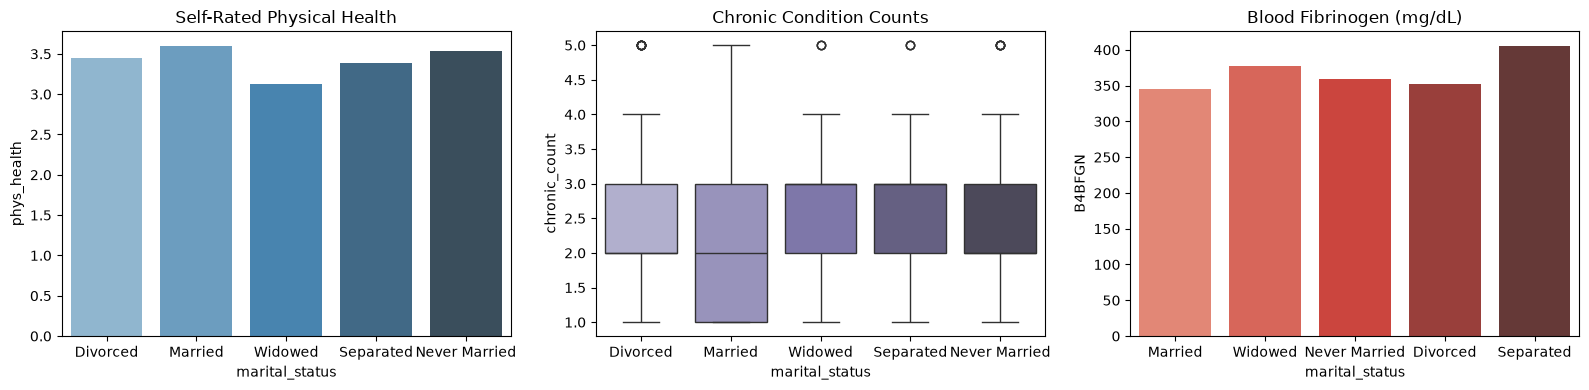

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=df_clean, x='marital_status', y='phys_health', ci=None, ax=axes[0], palette='Blues_d')
axes[0].set_title('Self-Rated Physical Health')

sns.boxplot(data=df_clean, x='marital_status', y='chronic_count', ax=axes[1], palette='Purples_d')
axes[1].set_title('Chronic Condition Counts')

sns.barplot(data=df_merged, x='marital_status', y='B4BFGN', ci=None, ax=axes[2], palette='Reds_d')
axes[2].set_title('Blood Fibrinogen (mg/dL)')

plt.tight_layout()
plt.show()